# Notebook 23b — Wu 2003 Summary Statistics for S-B3

Compute and validate reduced-scope summary-statistic views for the `S-B3` problem.
The underlying `S-B` summary construction is unchanged; the difference is that feed-fault
scenarios are out of scope and the endogenous target is the 4-vector
`[alpha, beta_r, eta_col, xi_reb]`.

This notebook inspects the **scenario-and-replicate** bank produced by notebook 22b. The
uniform-prior bank/branch is currently skipped upstream in notebook 22b
(`RUN_UNIFORM_PRIOR_BRANCH = False` there): uniform-prior sampling needs a fresh ODE solve per row,
and some draws are far too slow to make `N_TRAIN=5000` practical. This notebook is
scenario-and-replicate only until that branch is revisited. (Notebook 23's Section 7, "S-A vs S-B:
information value of x_D", also has no S-B3 counterpart here: `S-B3` keeps only the `S-B`
instrumentation, so there is no S-A comparison to make.)

**Contents:**
1. Load reduced-scope scenario-and-replicate training bank
2. Re-simulate deterministically for retained raw trajectories
3. Feature statistics table (S-B, reduced scope)
4. Build summary matrix for retained noisy replicates
5. PCA analysis of scenario-replicate summaries
6. t-SNE analysis of scenario-replicate summaries
7. Mutual-information analysis for the endogenous 4-D target
8. Save summary matrices for nb24b
9. Final acceptance criteria

In [6]:
import pathlib, sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
sys.path.insert(0, str(ROOT / 'src'))

import cstr_sbi.recycle.sb3 as sb3
sb3 = importlib.reload(sb3)
from cstr_sbi.recycle.sb3 import (
    PRIOR_HIGH_SB3_4D,
    PRIOR_LOW_SB3_4D,
    SB3_PARAM_NAMES,
    list_closed_loop_sb3,
    deterministic_window_sb3,
    noisy_replicates_sb3,
    fault_unit_sb3_truth,
 )
from cstr_sbi.recycle.summaries import compute_summaries, summary_names, N_SUMMARIES_SB

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)
OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#999999']

scenario_bank_path = DATA / 'wu2003_sbi_train_sb3_mixedwide_n5000.npz'
scenario_sbc_reduced_path = RESULTS / '24b_sysII_sb3_mixedwide_sbc_set_n120.npz'
scenario_sbc_confirm_path = RESULTS / '24b_sysII_sb3_mixedwide_sbc_set_n400.npz'

#scenario_bank_path = DATA / 'wu2003_sbi_train_sb3_scenario_replicates_n5000.npz'
#scenario_sbc_reduced_path = RESULTS / '24b_sysII_sb3_scenario_replicates_sbc_set_n120.npz'
#scenario_sbc_confirm_path = RESULTS / '24b_sysII_sb3_scenario_replicates_sbc_set_n400.npz'

if not scenario_bank_path.exists():
    raise FileNotFoundError('Run notebook 22b first to create the scenario-and-replicate S-B3 bank.')
scenario_bank = np.load(scenario_bank_path)
theta_train = np.asarray(scenario_bank['thetas4'], dtype=np.float32)
summary_train = np.asarray(scenario_bank['summaries'], dtype=np.float32)
sb_names = summary_names('S-B')
scenarios = list_closed_loop_sb3()
print('scenario bank:', scenario_bank_path.name, theta_train.shape, summary_train.shape)

scenario bank: wu2003_sbi_train_sb3_mixedwide_n5000.npz (5000, 4) (5000, 66)


## 1. Load Scenario-and-Replicate Reduced-Scope Bank

Loads the 4-D `S-B3` training bank produced by notebook 22b under the notebook-02-style
scenario-and-replicate recipe. This plays the same role as notebook 23's dataset-loading step,
but uses summary-bank rows directly because the reduced-scope workflow trains on summary vectors
rather than storing a full replicated observation archive.

In [7]:
print('Re-simulating retained scenarios to get 12-channel raw observations...')
raw_det_sb3 = {}
t_grid = None
for sc in scenarios:
    t_h, raw_sb = deterministic_window_sb3(sc, t_final_h=4.0, n_save=240)
    raw_det_sb3[sc.name] = np.asarray(raw_sb)
    if t_grid is None:
        t_grid = np.asarray(t_h)
    print(f'  {sc.name}')
print('Done.')

X_sb_det = np.stack([compute_summaries(raw_det_sb3[sc.name], 'S-B', t_grid) for sc in scenarios])
df_stats = pd.DataFrame({
    'feature': sb_names,
    'mean': X_sb_det.mean(axis=0),
    'std': X_sb_det.std(axis=0),
    'min': X_sb_det.min(axis=0),
    'max': X_sb_det.max(axis=0),
}).sort_values('std', ascending=False)

corr_rows = []
for j, pname in enumerate(SB3_PARAM_NAMES):
    corrs = [np.corrcoef(theta_train[:, j], summary_train[:, i])[0, 1] for i in range(summary_train.shape[1])]
    best = np.argsort(-np.abs(corrs))[:10]
    for idx in best:
        corr_rows.append({'parameter': pname, 'feature': sb_names[idx], 'corr': float(corrs[idx])})
corr_df = pd.DataFrame(corr_rows)

print(f'Top 20 most variable S-B features (reduced retained scenarios):')
print(df_stats.head(20).to_string(index=False))
corr_df

Re-simulating retained scenarios to get 12-channel raw observations...
  W1_healthy
  W2_cat_mild
  W3_cat_severe
  W4_cat_threshold
  W5_jacket_mild
  W6_jacket_severe
  W7_col_eff_mild
  W9_reb_fouling
  W11_reactor_combined
  W12_snowball_compound
  W15_snowball_threshold
  W16_full_multi
Done.
Top 20 most variable S-B features (reduced retained scenarios):
     feature      mean       std        min       max
 Q_reb_slope -1.466204 10.612982 -13.997431 12.923183
   Q_j_slope  3.955869 10.602239 -11.751765 12.996829
   Q_reb_std 10.770531  4.326094   2.248601 14.160677
     Q_j_std 11.837249  2.552623   6.242340 13.525954
   T_reb_std  0.711329  0.717189   0.000007  1.885573
 T_reb_slope  0.595836  0.701248  -0.213701  1.748173
     Q_j_min 15.493489  0.592724  14.225794 16.048719
corr_Qreb_FR -0.209315  0.415213  -0.689236  0.450505
   Q_reb_min 15.972465  0.269135  15.745903 16.589298
  corr_Qj_FR  0.397483  0.242784  -0.020465  0.692516
    Q_j_mean 15.825986  0.230580  15.390782

,parameter,feature,corr
0,alpha,recycle_excess,-0.999048
1,alpha,recycle_ratio,-0.999013
2,alpha,F_R_norm_mean,-0.999013
3,alpha,col_recovery,0.999013
4,alpha,F_R_norm_q_mean,-0.998998
5,alpha,F_R_norm_slope,-0.998595
6,alpha,F_R_norm_max,-0.981618
7,alpha,Q_j_mean,0.969390
8,alpha,T_r_mean,0.967993
9,alpha,Q_j_q_mean,0.956364


## 2. Re-simulate Deterministically for Retained Raw Trajectories

Notebook 23 re-simulated deterministic raw trajectories before building summary diagnostics.
This reduced-scope version does the same, but only for the retained `S-B3` scenario set and over
the longer 4-hour window adopted in notebook 22b.

## 3. Feature Statistics Table (S-B, reduced scope)

The first representation check is which summary features still vary meaningfully across the retained
scenario set and how strongly they correlate with the endogenous 4-D target.

In [8]:
print('Building reduced-scope noisy summary matrix (10 replicates per retained scenario)...')
X_sb_rep = []
labels_rep = []
for sc in scenarios:
    raw = raw_det_sb3[sc.name]
    rng = np.random.default_rng(230001 + sc.id)
    reps = noisy_replicates_sb3(raw, n_replicates=10, rng=rng, noise_pct=0.003)
    for rep_idx in range(10):
        summary = compute_summaries(reps[rep_idx], 'S-B', t_grid)
        X_sb_rep.append(summary)
        labels_rep.append({
            'scenario': sc.name,
            'fault_unit_sb3': sb3.fault_unit_sb3_truth(np.asarray(sc.theta())[:4]),
            'alpha': float(sc.alpha),
            'beta_r': float(sc.beta_r),
            'eta_col': float(sc.eta_col),
            'xi_reb': float(sc.xi_reb),
        })
X_sb_rep = np.asarray(X_sb_rep, dtype=np.float32)
labels_rep_df = pd.DataFrame(labels_rep)

scenario_rows = []
for sc_name in labels_rep_df['scenario'].unique():
    block = X_sb_rep[labels_rep_df['scenario'] == sc_name]
    scenario_rows.append({
        'scenario': sc_name,
        'mean_summary_norm': float(np.mean(np.linalg.norm(block, axis=1))),
        'std_summary_norm': float(np.std(np.linalg.norm(block, axis=1))),
    })
scenario_df = pd.DataFrame(scenario_rows)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sb_rep)
print('X_sb_rep shape:', X_sb_rep.shape)
scenario_df

Building reduced-scope noisy summary matrix (10 replicates per retained scenario)...
X_sb_rep shape: (120, 66)


,scenario,mean_summary_norm,std_summary_norm
0,W1_healthy,54.826546,0.128210
1,W2_cat_mild,57.904968,0.004021
2,W3_cat_severe,57.448414,0.003669
3,W4_cat_threshold,57.272949,0.270111
4,W5_jacket_mild,55.898121,0.104612
5,W6_jacket_severe,56.384399,0.072782
6,W7_col_eff_mild,56.814026,0.006719
7,W9_reb_fouling,55.280804,0.199896
8,W11_reactor_combined,57.807262,0.003189
9,W12_snowball_compound,57.282982,0.006857


## 4. Build Summary Matrix for Retained Noisy Replicates

This mirrors notebook 23's summary-matrix construction step in a lighter reduced-scope form:
10 noisy replicates per retained scenario are enough for PCA, t-SNE, and mutual-information sanity
checks without recreating the full original observation archive.

## 5. PCA Analysis

PCA provides a cheap visual check of whether the retained `S-B3` summary representation still
separates healthy, reactor-side, column-side, and compound behavior at all.

## 6. t-SNE Analysis

t-SNE is kept here for the same reason as in notebook 23: a nonlinear view can show whether the
retained scenarios cluster by fault class or collapse onto each other under the summary map.

## 7. Mutual Information Analysis

Finally, feature-to-parameter mutual information gives a model-free check of which endogenous
parameters remain most strongly represented under the reduced scope.

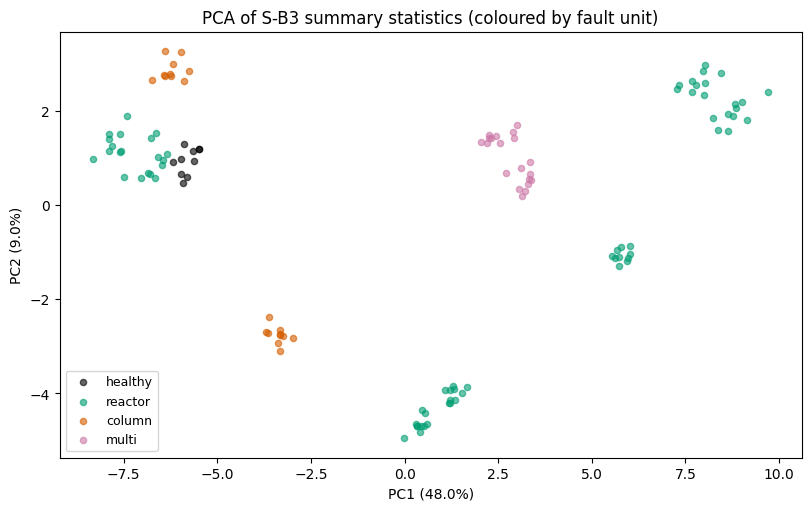

Saved nb23b_pca_sb3.png


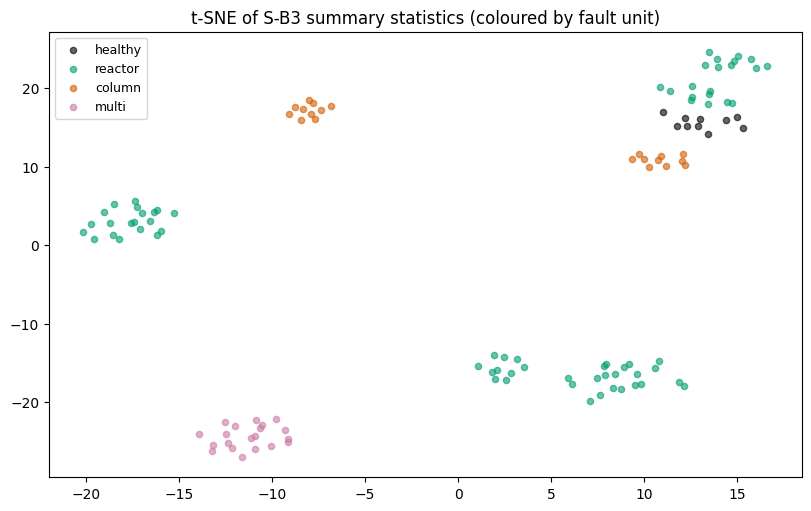

Saved nb23b_tsne_sb3.png
parameter         feature  mutual_info
    alpha         Q_j_min     1.724173
    alpha        Qj_slope     1.724173
    alpha     Q_reb_slope     1.724173
    alpha      Q_reb_mean     1.724173
    alpha  reb_per_boilup     1.724173
    alpha      Q_j_q_mean     1.724173
    alpha F_R_norm_q_mean     1.724173
    alpha    V_norm_slope     1.724173
    alpha       Q_j_slope     1.724173
    alpha     V_norm_mean     1.724173
   beta_r        Qj_slope     0.832388
   beta_r       Q_j_slope     0.832388
   beta_r        Q_j_mean     0.832388
   beta_r        UA_proxy     0.825595
   beta_r        T_j_mean     0.824749
   beta_r         Q_j_min     0.730903
   beta_r         Q_j_std     0.708436
   beta_r     Tr_Tj_ratio     0.706963
   beta_r      T_j_q_mean     0.685977
   beta_r     V_norm_mean     0.661177


In [9]:
unit_order = ['healthy', 'reactor', 'column', 'multi']
unit_colors = {'healthy': OI[0], 'reactor': OI[3], 'column': OI[6], 'multi': OI[7]}

pca = PCA(n_components=2)
Z_pca = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for unit in unit_order:
    mask = labels_rep_df['fault_unit_sb3'].values == unit
    if not mask.any():
        continue
    ax.scatter(Z_pca[mask, 0], Z_pca[mask, 1], label=unit, alpha=0.6, s=20, color=unit_colors[unit])
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('PCA of S-B3 summary statistics (coloured by fault unit)')
ax.legend(fontsize=9)
plt.savefig(FIGURES / 'nb23b_pca_sb3.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb23b_pca_sb3.png')

perplexity = min(20, max(5, len(X_scaled) // 10))
Z_tsne = TSNE(n_components=2, init='pca', learning_rate='auto', perplexity=perplexity, random_state=230123).fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for unit in unit_order:
    mask = labels_rep_df['fault_unit_sb3'].values == unit
    if not mask.any():
        continue
    ax.scatter(Z_tsne[mask, 0], Z_tsne[mask, 1], label=unit, alpha=0.6, s=20, color=unit_colors[unit])
ax.set_title('t-SNE of S-B3 summary statistics (coloured by fault unit)')
ax.legend(fontsize=9)
plt.savefig(FIGURES / 'nb23b_tsne_sb3.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb23b_tsne_sb3.png')

mi_rows = []
for j, pname in enumerate(SB3_PARAM_NAMES):
    y_param = labels_rep_df[pname].values.astype(float)
    mi = mutual_info_regression(X_scaled, y_param, random_state=230123)
    best = np.argsort(-mi)[:10]
    for idx in best:
        mi_rows.append({'parameter': pname, 'feature': sb_names[idx], 'mutual_info': float(mi[idx])})
mi_df = pd.DataFrame(mi_rows)
print(mi_df.head(20).to_string(index=False))

## 8. Save Summary Matrices for nb24b

Mirrors notebook 23's final step: persist the labeled summary matrix built above (12 retained
scenarios x 10 noisy replicates each) so downstream notebooks can load it directly instead of
re-simulating. Saved as `wu2003_summary_features_sb3.npz`, analogous to notebook 23's
`wu2003_summary_features.npz`.

In [10]:
np.savez(
    DATA / 'wu2003_summary_features_sb3.npz',
    X_sb=X_sb_rep,
    labels_sb=labels_rep_df.to_records(index=False),
    sb_feature_names=np.array(sb_names, dtype=object),
)
print(f"Saved summary features to {DATA / 'wu2003_summary_features_sb3.npz'}")
print(f'  X_sb: {X_sb_rep.shape}   ({X_sb_rep.shape[0]} rows x {N_SUMMARIES_SB})')
print()
print('=== Notebook 23b (scenario-and-replicate branch) complete ===')

Saved summary features to /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/wu2003_summary_features_sb3.npz
  X_sb: (120, 66)   (120 rows x 66)

=== Notebook 23b (scenario-and-replicate branch) complete ===


## 9. Final acceptance criteria

This notebook passes if:
1. the scenario-and-replicate bank loads with the expected summary dimension,
2. each endogenous parameter has at least one materially correlated summary feature,
3. the retained scenarios show nontrivial spread in summary norms under noise,
4. both scenario-and-replicate SBC sets (reduced and confirm) load, match the training bank's summary
   dimension, and are free of non-finite values.

In [11]:
def load_sbc_set(path):
    if not path.exists():
        raise FileNotFoundError(f'Run notebook 22b (scenario-and-replicate branch) first to create {path.name}.')
    data = np.load(path)
    return np.asarray(data['thetas4'], dtype=np.float32), np.asarray(data['summaries'], dtype=np.float32)

theta_sbc_r, summary_sbc_r = load_sbc_set(scenario_sbc_reduced_path)
theta_sbc_c, summary_sbc_c = load_sbc_set(scenario_sbc_confirm_path)

best_abs_corr = corr_df.groupby('parameter')['corr'].apply(lambda s: float(np.max(np.abs(s))))
criteria = [
    ('scenario bank summary dimension matches S-B names', summary_train.shape[1] == len(sb_names), f"{summary_train.shape[1]} vs {len(sb_names)}"),
    ('each parameter has |corr| >= 0.20 in scenario bank', bool((best_abs_corr >= 0.20).all()), best_abs_corr.to_dict()),
    ('scenario summary norms vary under retained catalogue', float(scenario_df['std_summary_norm'].mean()) > 0.0, f"mean std={scenario_df['std_summary_norm'].mean():.4f}"),
    ('scenario SBC reduced set matches training summary dimension and is finite',
     summary_sbc_r.shape[1] == summary_train.shape[1] and bool(np.isfinite(theta_sbc_r).all() and np.isfinite(summary_sbc_r).all()),
     f"rows={theta_sbc_r.shape[0]}, summary_dim={summary_sbc_r.shape[1]}"),
    ('scenario SBC confirm set matches training summary dimension and is finite',
     summary_sbc_c.shape[1] == summary_train.shape[1] and bool(np.isfinite(theta_sbc_c).all() and np.isfinite(summary_sbc_c).all()),
     f"rows={theta_sbc_c.shape[0]}, summary_dim={summary_sbc_c.shape[1]}"),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

PASS | scenario bank summary dimension matches S-B names: 66 vs 66
PASS | each parameter has |corr| >= 0.20 in scenario bank: {'alpha': 0.9990476288205281, 'beta_r': 0.7549884180710938, 'eta_col': 0.4638300168258411, 'xi_reb': 0.9417600858277078}
PASS | scenario summary norms vary under retained catalogue: mean std=0.0679
PASS | scenario SBC reduced set matches training summary dimension and is finite: rows=120, summary_dim=66
PASS | scenario SBC confirm set matches training summary dimension and is finite: rows=400, summary_dim=66
